In [2]:
import html
import re
import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36",
    "Accept-Language": "vi-VN,vi;q=0.9,en-US;q=0.8"
}
print("Đã nạp thư viện thành công!")


Đã nạp thư viện thành công!


In [4]:
raw_records = []

# 1. Cào từ Public API của CHỢ TỐT (Lấy 5 trang = ~250 tin đăng)
try:
    chotot_count = 0
    for page in range(1, 6):
        offset = (page - 1) * 50
        url = f"https://gateway.chotot.com/v1/public/ad-listing?cg=5010&limit=50&o={offset}&st=s,k"
        res = requests.get(url, headers=HEADERS, timeout=8).json()
        for ad in res.get("ads", []):
            raw_records.append({
                "source": "Chợ Tốt",
                "title_raw": ad.get("subject", ""),
                "price_raw": ad.get("price_string", "Liên hệ")
            })
            chotot_count += 1
    print(f"[1/7] Chợ Tốt API: Thu thập được {chotot_count} dòng.")
except Exception as e:
    print(f"[1/7] Chợ Tốt tạm thời không phản hồi: {e}")

# 2. Hàm cào tổng quát cho các trang HTML bán lẻ ĐTDĐ tại Việt Nam
def scrape_retail_html(source_name, url_list):
    count = 0
    for url in url_list:
        try:
            resp = requests.get(url, headers=HEADERS, timeout=10)
            text_html = html.unescape(resp.text)
            pattern = r'<(?:h[234]|a)[^>]*>([^<]*(?:iPhone|Samsung|Galaxy|Xiaomi|Redmi|Oppo)[^<]*)</(?:h[234]|a)>.*?(\d{1,2}[\.,]\d{3}[\.,]\d{3})'
            for match in re.finditer(pattern, text_html, re.S | re.I):
                title = re.sub(r'\s+', ' ', match.group(1)).strip()
                price = match.group(2).strip()
                if 5 < len(title) < 120:
                    raw_records.append({
                        "source": source_name,
                        "title_raw": title,
                        "price_raw": price
                    })
                    count += 1
        except Exception:
            pass
    print(f"[+] {source_name}: Thu thập được {count} dòng.")

scrape_retail_html("Điện Thoại Vui (CellphoneS)", [
    "https://dienthoaivui.com.vn/may-cu/dien-thoai-cu",
    "https://dienthoaivui.com.vn/may-cu/iphone-cu",
    "https://dienthoaivui.com.vn/may-cu/samsung-cu"
])
scrape_retail_html("Minh Tuấn Mobile", [
    "https://minhtuanmobile.com/may-cu/",
    "https://minhtuanmobile.com/may-cu/?page=2",
    "https://minhtuanmobile.com/may-cu/?page=3"
])
scrape_retail_html("FPT Shop", ["https://fptshop.com.vn/may-doi-tra"])
scrape_retail_html("Hoàng Hà Mobile", ["https://hoanghamobile.com/kho-san-pham-cu"])
scrape_retail_html("24hStore", ["https://24hstore.vn/dien-thoai-cu", "https://24hstore.vn/iphone-cu"])
scrape_retail_html("Clickbuy", ["https://clickbuy.com.vn/danh-muc/hang-cu/"])

df_raw = pd.DataFrame(raw_records)
df_raw.to_csv("../data/raw/1_dienthoai_cu_raw.csv", index=False, encoding="utf-8-sig")

print(f"\n=> TỔNG CỘNG ĐÃ CÀO ĐƯỢC: {len(df_raw)} dòng dữ liệu thô!")
print(df_raw["source"].value_counts())
display(df_raw.sample(min(10, len(df_raw)), random_state=42))



[1/7] Chợ Tốt API: Thu thập được 250 dòng.
[+] Điện Thoại Vui (CellphoneS): Thu thập được 60 dòng.
[+] Minh Tuấn Mobile: Thu thập được 87 dòng.
[+] FPT Shop: Thu thập được 12 dòng.
[+] Hoàng Hà Mobile: Thu thập được 74 dòng.
[+] 24hStore: Thu thập được 74 dòng.
[+] Clickbuy: Thu thập được 1 dòng.

=> TỔNG CỘNG ĐÃ CÀO ĐƯỢC: 558 dòng dữ liệu thô!
source
Chợ Tốt                        250
Minh Tuấn Mobile                87
Hoàng Hà Mobile                 74
24hStore                        74
Điện Thoại Vui (CellphoneS)     60
FPT Shop                        12
Clickbuy                         1
Name: count, dtype: int64


,source,title_raw,price_raw
158,Chợ Tốt,APPLE IPHONE 8 64GB MÁY ZIN PIN 100%,980.000 đ
451,Hoàng Hà Mobile,Samsung Galaxy Tab S10 Lite Wifi 6GB/128GB - M...,"7,250,000"
55,Chợ Tốt,GOOGLE PIXEL 6 TRẮNG,1.900.000 đ
247,Chợ Tốt,Oppo A17 Xanh,1.500.000 đ
70,Chợ Tốt,XIAOMI REDMI NOTE 10 PRO 8GB/128GB ĐỒNG,2.300.000 đ
376,Minh Tuấn Mobile,iPhone 14 Pro Max 128GB - Cũ đẹp,"16,790,000"
382,Minh Tuấn Mobile,iPhone 16 Pro Max 512GB - Cũ đẹp,"28,490,000"
81,Chợ Tốt,Bán nhanh $$$$$,6.333.000 đ
516,24hStore,Xiaomi Redmi Pad 2 Wifi 9.7 inch 4GB/64GB Chín...,3.690.000
144,Chợ Tốt,Xiaomi Redmi K30 Ultra 8GB/512GB Đen,2.800.000 đ


In [5]:
df = df_raw.copy()

# 1. Xóa dòng trùng lặp
initial_len = len(df)
df = df.drop_duplicates(subset=["source", "title_raw", "price_raw"]).copy()
print(f"Đã xóa {initial_len - len(df)} dòng trùng lặp.")

# 2. Làm sạch cột Giá tiền -> Đơn vị: Triệu VNĐ
def clean_price_vn(p_str):
    s = str(p_str).lower().strip()
    if "liên hệ" in s or s == "":
        return np.nan
    if "triệu" in s or "tr" in s:
        nums = re.findall(r"\d+[\.,]?\d*", s)
        if nums:
            return float(nums[0].replace(",", "."))
    digits = re.sub(r"[^\d]", "", s)
    if digits:
        return round(float(digits) / 1_000_000, 2)
    return np.nan

df["price_trieu"] = df["price_raw"].apply(clean_price_vn)
df = df.dropna(subset=["price_trieu"])
# Lọc bỏ phụ kiện/ốp lưng (< 1.5 triệu) hoặc giá lỗi (> 65 triệu)
df = df[(df["price_trieu"] >= 1.5) & (df["price_trieu"] <= 65.0)].copy()

# 3. Trích xuất Hãng sản xuất (Brand)
def extract_brand(title):
    t = str(title).lower()
    if any(k in t for k in ["iphone", "ip ", "promax"]):
        return "Apple"
    if any(k in t for k in ["samsung", "galaxy", "z fold", "z flip", "s21", "s22", "s23", "s24"]):
        return "Samsung"
    if any(k in t for k in ["xiaomi", "redmi", "poco"]):
        return "Xiaomi"
    if any(k in t for k in ["oppo", "reno", "find x"]):
        return "Oppo"
    return "Other"

df["brand"] = df["title_raw"].apply(extract_brand)
df = df[df["brand"] != "Other"].copy()

# 4. Trích xuất Đời máy (Model Generation)
def extract_model_gen(title):
    t = str(title).lower()
    m_ip = re.search(r"(?:iphone|ip)\s*(\d{1,2})", t)
    if m_ip:
        gen = float(m_ip.group(1))
        if 7 <= gen <= 18:
            return gen
    m_ss = re.search(r"s(2\d)", t)
    if m_ss:
        return float(m_ss.group(1)) - 8.0
    m_fold = re.search(r"(?:fold|flip)\s*(\d)", t)
    if m_fold:
        return float(m_fold.group(1)) + 10.0
    return 12.0

df["model_gen"] = df["title_raw"].apply(extract_model_gen)

# 5. Trích xuất Phiên bản (0: Thường, 1: Plus/Pro/Flip, 2: Pro Max/Ultra/Fold)
def extract_variant_tier(title):
    t = str(title).lower()
    if any(k in t for k in ["pro max", "promax", "ultra", "fold"]):
        return 2
    if any(k in t for k in ["pro", "plus", "flip", "fe"]):
        return 1
    return 0

df["variant_tier"] = df["title_raw"].apply(extract_variant_tier)

# 6. Trích xuất Dung lượng bộ nhớ ROM (GB)
def extract_rom_gb(title):
    t = str(title).upper()
    if "1TB" in t or "1024GB" in t:
        return 1024.0
    matches = re.findall(r"(64|128|256|512)\s*G?B?", t)
    if matches:
        return float(matches[-1])
    return 128.0

df["rom_gb"] = df["title_raw"].apply(extract_rom_gb)

# 7. Đồng nhất Tình trạng ngoại hình (%)
def standardize_condition(title):
    t = str(title).lower()
    if any(k in t for k in ["95%", "xước cấn", "cấn"]):
        return 95.0
    if any(k in t for k in ["97%", "98%", "trầy"]):
        return 97.0
    if any(k in t for k in ["99%", "cũ đẹp", "like new", "kích hoạt", "demo", "tbh"]):
        return 99.0
    return 97.0

df["condition_pct"] = df["title_raw"].apply(standardize_condition)

cols_clean = ["source", "brand", "title_raw", "model_gen", "variant_tier", "rom_gb", "condition_pct", "price_trieu"]
df_clean = df[cols_clean].dropna().copy()
df_clean.to_csv("../data/processed/2_dienthoai_cu_clean.csv", index=False, encoding="utf-8-sig")

print(f"Số lượng mẫu sạch hợp lệ sau khi chuẩn hóa: {len(df_clean)} máy")
display(df_clean.head(10))


Đã xóa 122 dòng trùng lặp.
Số lượng mẫu sạch hợp lệ sau khi chuẩn hóa: 357 máy


,source,brand,title_raw,model_gen,variant_tier,rom_gb,condition_pct,price_trieu
1,Chợ Tốt,Apple,IPHONE 11 PRO MAX 64GB GOLD 99% ẨN ILAO SÀI FULL,11.0,2,64.0,99.0,2.90
3,Chợ Tốt,Apple,IPHONE 11 QT- 128GB TRẮNG đang xài..,11.0,0,128.0,97.0,2.60
5,Chợ Tốt,Xiaomi,Xiaomi 13 Pro 8GB/128GB,12.0,1,128.0,97.0,2.20
8,Chợ Tốt,Apple,Apple iPhone 14 Pro Max 256GB Tím Mỹ,14.0,2,256.0,97.0,8.20
11,Chợ Tốt,Xiaomi,Xiaomi 17 12GB/512GB Hồng,12.0,0,512.0,97.0,14.99
13,Chợ Tốt,Xiaomi,Xiaomi 14 Pro 12/256g rom quốc tế,12.0,1,256.0,97.0,7.70
14,Chợ Tốt,Apple,Apple iPhone 11 Pro Max 64GB Đen 100%,11.0,2,64.0,97.0,5.10
15,Chợ Tốt,Apple,Apple iPhone 6s +11 pro,12.0,1,128.0,97.0,2.70
16,Chợ Tốt,Samsung,Samsung S26 256G Đen Việt Nam fullbox newseal ...,18.0,0,256.0,97.0,17.99
17,Chợ Tốt,Xiaomi,Xiaomi K50 Pro 8GB/128GB Bạc,12.0,1,128.0,97.0,2.95


C:\Users\SinhVien\AppData\Local\Temp\ipykernel_13620\1381254851.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="price_trieu", y="source", palette="Set2")


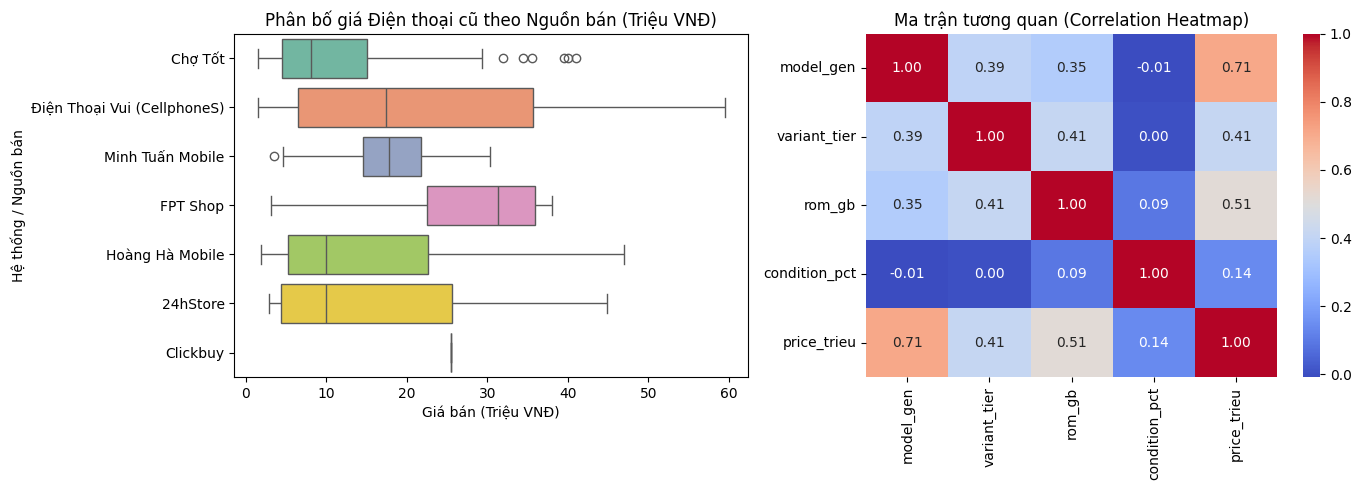

In [6]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df_clean, x="price_trieu", y="source", palette="Set2")
plt.title("Phân bố giá Điện thoại cũ theo Nguồn bán (Triệu VNĐ)")
plt.xlabel("Giá bán (Triệu VNĐ)")
plt.ylabel("Hệ thống / Nguồn bán")

plt.subplot(1, 2, 2)
num_cols = ["model_gen", "variant_tier", "rom_gb", "condition_pct", "price_trieu"]
sns.heatmap(df_clean[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Ma trận tương quan (Correlation Heatmap)")

plt.tight_layout()
plt.show()


In [7]:
df_ml = pd.get_dummies(
    df_clean.drop(columns=["title_raw"]),
    columns=["source", "brand"],
    drop_first=False
)

X = df_ml.drop(columns=["price_trieu"])
y = df_ml["price_trieu"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# 2. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=150, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

results = pd.DataFrame([
    {
        "Mô hình": "Linear Regression",
        "MAE (Triệu VNĐ)": round(mean_absolute_error(y_test, y_pred_lr), 2),
        "RMSE (Triệu VNĐ)": round(np.sqrt(mean_squared_error(y_test, y_pred_lr)), 2),
        "R2 Score (%)": round(r2_score(y_test, y_pred_lr) * 100, 2)
    },
    {
        "Mô hình": "Random Forest Regressor",
        "MAE (Triệu VNĐ)": round(mean_absolute_error(y_test, y_pred_rf), 2),
        "RMSE (Triệu VNĐ)": round(np.sqrt(mean_squared_error(y_test, y_pred_rf)), 2),
        "R2 Score (%)": round(r2_score(y_test, y_pred_rf) * 100, 2)
    }
])

print("=== BẢNG SO SÁNH HIỆU QUẢ MÔ HÌNH ===")
display(results)


=== BẢNG SO SÁNH HIỆU QUẢ MÔ HÌNH ===


,Mô hình,MAE (Triệu VNĐ),RMSE (Triệu VNĐ),R2 Score (%)
0,Linear Regression,3.68,5.05,79.05
1,Random Forest Regressor,2.85,4.84,80.72


In [8]:
print("=== DỰ ĐOÁN GIÁ: iPhone 15 Pro Max 256GB (Đẹp 99%) TẠI CÁC HỆ THỐNG ===")

for shop in df_clean["source"].unique():
    sample = pd.DataFrame(0, index=[0], columns=X.columns)
    sample["model_gen"] = 15.0
    sample["variant_tier"] = 2
    sample["rom_gb"] = 256.0
    sample["condition_pct"] = 99.0
    
    if "brand_Apple" in sample.columns:
        sample["brand_Apple"] = 1
    if f"source_{shop}" in sample.columns:
        sample[f"source_{shop}"] = 1
        
    pred_price = rf_model.predict(sample)[0]
    print(f"  + Tại [{shop:<28}]: {pred_price:.2f} Triệu VNĐ (~ {pred_price*1_000_000:,.0f} ₫)")


=== DỰ ĐOÁN GIÁ: iPhone 15 Pro Max 256GB (Đẹp 99%) TẠI CÁC HỆ THỐNG ===
  + Tại [Chợ Tốt                     ]: 26.94 Triệu VNĐ (~ 26,935,505 ₫)
  + Tại [Điện Thoại Vui (CellphoneS) ]: 14.60 Triệu VNĐ (~ 14,601,586 ₫)
  + Tại [Minh Tuấn Mobile            ]: 20.81 Triệu VNĐ (~ 20,809,433 ₫)
  + Tại [FPT Shop                    ]: 20.35 Triệu VNĐ (~ 20,345,460 ₫)
  + Tại [Hoàng Hà Mobile             ]: 17.54 Triệu VNĐ (~ 17,541,599 ₫)
  + Tại [24hStore                    ]: 20.82 Triệu VNĐ (~ 20,819,815 ₫)
  + Tại [Clickbuy                    ]: 18.80 Triệu VNĐ (~ 18,797,148 ₫)
